#  1.Kiểm tra chất lượng dữ liệu giao thông  
Mục tiêu:  
1. Kiểm tra kích thước, tên cột và kiểu dữ liệu.
2. Kiểm tra giá trị thiếu và ô rỗng.
3. Kiểm tra dòng trùng và timestamp trùng.
4. Kiểm tra timestamp hợp lệ, thứ tự thời gian và giờ bị thiếu.
5. Kiểm tra các giá trị bất hợp lý.
6. Tổng hợp vấn đề để chuẩn bị tiền xử lý.

Notebook này chưa xóa dòng, điền thiếu hoặc tạo đặc trưng.

## Import thư viện

In [1]:
from pathlib import Path
import pandas as pd

## xác định đường dẫn 

In [2]:

cwd = Path.cwd().resolve()
PROJECT_DIR = next((p for p in (cwd, *cwd.parents) if (p / "data" / "Metro_Interstate_Traffic_Volume.csv").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Không tìm thấy CSV trong thư mục dự án.")

DATA_PATH = PROJECT_DIR / "data" / "Metro_Interstate_Traffic_Volume.csv"

print("Đường dẫn dữ liệu:", DATA_PATH)
print("File tồn tại:", DATA_PATH.is_file())

Đường dẫn dữ liệu: e:\Project\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\data\Metro_Interstate_Traffic_Volume.csv
File tồn tại: True


## Đọc và xem dữ liệu

In [3]:
df_raw = pd.read_csv(
    DATA_PATH,
    keep_default_na=False
)

# Bản sao dùng để kiểm tra, giữ nguyên df_raw
df = df_raw.copy(deep=True)

print(f"Số dòng: {df_raw.shape[0]:,}")
print(f"Số cột: {df_raw.shape[1]}")
print("\nTên các cột:")
print(df_raw.columns.tolist())

display(df_raw.head())

Số dòng: 48,204
Số cột: 9

Tên các cột:
['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


Nhận xét:
- Dữ liệu có 48.204 dòng và 9 cột. Mức độ phù hợp cho từng mô hình sẽ được đánh giá sau khi kiểm tra chất lượng dữ liệu, chia tập theo thời gian và thực nghiệm.  
- Dữ liệu gồm 8 cột đầu vào và biến mục tiêu traffic_volume. Có thể khai thác thêm đặc trưng từ date_time như giờ, thứ trong tuần, tháng và cuối tuần; hiệu quả của các đặc trưng này cần được kiểm chứng trên tập validation.

## Kiểm tra cấu trúc và kiểu dữ liệu

Các cột được chia thành:
- Thời gian: date_time.
- Số: temp, rain_1h, snow_1h, clouds_all, traffic_volume.
- Phân loại: holiday, weather_main, weather_description.

Kiểm tra CSV có đủ các cột dự kiến, có cột ngoài dự kiến hay không; đồng thời quan sát kiểu dữ liệu và số giá trị non-null của từng cột.

In [4]:
numeric_cols = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume",
]

categorical_cols = [
    "holiday",
    "weather_main",
    "weather_description",
]

expected_cols = categorical_cols + numeric_cols + ["date_time"]

missing_cols = sorted(set(expected_cols) - set(df_raw.columns))
extra_cols = sorted(set(df_raw.columns) - set(expected_cols))

print("Cột còn thiếu:", missing_cols)
print("Cột ngoài dự kiến:", extra_cols)

if missing_cols:
    raise ValueError(f"Dữ liệu thiếu các cột bắt buộc: {missing_cols}")

df_raw.info()

Cột còn thiếu: []
Cột ngoài dự kiến: []
<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              48204 non-null  str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


nhận xét:
- Nhìn chung Cả 9 cột đều có 48.204 giá trị non-null theo `df_raw.info()`. Do dữ liệu được đọc với `keep_default_na=False`, cần kiểm tra thêm chuỗi rỗng, chuỗi chỉ chứa khoảng trắng và các ký hiệu biểu thị thiếu trước khi quyết định xử lý.
- Các cột temp, rain_1h, snow_1h có kiểu float64; clouds_all và traffic_volume có kiểu int64, phù hợp với nhóm biến số dự kiến. Cần kiểm tra thêm miền giá trị.
- `date_time` hiện có kiểu `object`. Cần chuyển sang kiểu `datetime` và kiểm tra các giá trị chuyển đổi không thành công trước khi kiểm tra chuỗi thời gian hoặc tạo đặc trưng thời gian.
- `holiday` có 48.204 giá trị non-null; các dòng đầu hiển thị chuỗi "None". Cần xác nhận ý nghĩa các giá trị bằng mô tả dữ liệu.
- Không thiếu giá trị” không có nghĩa là “dữ liệu sạch”.`df.info()` chỉ phát hiện ô trống, không phát hiện giá trị sai. Cần kiểm tra các giá trị nhiệt độ bất hợp lý, lượng mưa bất thường và timestamp lặp. Chỉ kết luận sau khi xác định số lượng, ví dụ cụ thể và ngữ cảnh của từng hiện tượng.

## Kiểm tra tên cột

In [5]:
# Kiểm tra tên cột, tên trùng và khoảng trắng thừa
print("Số cột:", len(df_raw.columns))
print("Tên cột:", df_raw.columns.tolist())
print("Tên cột trùng:", df_raw.columns[df_raw.columns.duplicated()].tolist())
print(
    "Tên cột có khoảng trắng đầu/cuối:",
    [col for col in df_raw.columns if col != col.strip()]
)

Số cột: 9
Tên cột: ['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']
Tên cột trùng: []
Tên cột có khoảng trắng đầu/cuối: []


Nhận xét:
- Dữ liệu có đủ 9 cột theo danh sách dự kiến, không thiếu cột và không có cột ngoài dự kiến.
- Không phát hiện tên cột trùng hoặc khoảng trắng ở đầu/cuối tên cột.
- Tên cột hiện tại có thể sử dụng trực tiếp cho các bước kiểm tra tiếp theo, chưa cần đổi tên.

## Kiểm tra giá trị thiếu và ô rỗng

In [6]:
# Đếm riêng null và chuỗi rỗng/chỉ chứa khoảng trắng
missing_summary = pd.DataFrame({
    "null_count": df_raw.isna().sum(),
    "blank_count": df_raw.apply(
        lambda col: col.astype("string")
        .str.fullmatch(r"\s*", na=False).sum()
    ),
})

display(missing_summary)

,null_count,blank_count
holiday,0,0
temp,0,0
rain_1h,0,0
snow_1h,0,0
clouds_all,0,0
weather_main,0,0
weather_description,0,0
date_time,0,0
traffic_volume,0,0


Nhận xét:
- Cả 9 cột đều có `null_count = 0` và `blank_count = 0`. Trên 48.204 dòng, không phát hiện giá trị null, chuỗi rỗng hoặc chuỗi chỉ chứa khoảng trắng theo hai phép kiểm tra này.
- Chưa có giá trị thiếu dạng null hoặc chuỗi rỗng cần điền theo kết quả trên. Các ký hiệu đặc biệt như chuỗi "None" trong holiday cần được xác nhận ý nghĩa riêng trước khi quyết định có phải giá trị thiếu hay không.
- Kết quả này chưa đủ để kết luận dữ liệu hoàn toàn sạch; vẫn cần kiểm tra `timestamp`, dữ liệu trùng và miền giá trị.

## Kiểm tra tính hợp lệ của timestamp

In [7]:
# Chuyển thử để kiểm tra, giữ nguyên df_raw
date_time_parsed = pd.to_datetime(
    df_raw["date_time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

invalid_time = date_time_parsed.isna()

print("Số timestamp không hợp lệ:", invalid_time.sum())
print("Thời gian sớm nhất:", date_time_parsed.min())
print("Thời gian muộn nhất:", date_time_parsed.max())

# Hiển thị ví dụ nếu có giá trị chuyển đổi thất bại
display(df_raw.loc[invalid_time, ["date_time"]].head(10))

Số timestamp không hợp lệ: 0
Thời gian sớm nhất: 2012-10-02 09:00:00
Thời gian muộn nhất: 2018-09-30 23:00:00


,date_time


Nhận xét:
- Cả 48.204 giá trị trong `date_time` đều chuyển đổi được sang datetime theo định dạng `%Y-%m-%d %H:%M:%S`; không phát hiện giá trị chuyển đổi thất bại (`NaT`).
- Thời gian sớm nhất là `2012-10-02 09:00:00`, thời gian muộn nhất là `2018-09-30 23:00:00`.
- Bảng ví dụ lỗi rỗng vì không có timestamp chuyển đổi thất bại; chưa cần loại dòng do lỗi chuyển đổi timestamp ở bước này.
- Kết quả này xác nhận khả năng chuyển đổi thời gian, chưa chứng minh dữ liệu được sắp xếp theo thời gian, không có timestamp lặp hoặc không thiếu giờ. Cần kiểm tra riêng các nội dung này.

## kiểm tra dòng trùng và timestamp  lặp

In [8]:
# Số dòng trùng hoàn toàn, không tính bản xuất hiện đầu tiên
duplicate_rows = df_raw.duplicated()

# Đếm số bản ghi tại mỗi timestamp đã chuyển đổi
time_counts = date_time_parsed.value_counts()
repeated_times = time_counts[time_counts > 1]

print("Số dòng trùng hoàn toàn (ngoài bản đầu):", duplicate_rows.sum())
print("Số timestamp duy nhất:", date_time_parsed.nunique())
print("Số timestamp xuất hiện nhiều lần:", len(repeated_times))
print("Tổng số dòng thuộc các timestamp lặp:", repeated_times.sum())

# Xem các bản ghi cùng thời điểm để so sánh
repeated_mask = date_time_parsed.duplicated(keep=False)
display(
    df_raw.loc[repeated_mask]
    .sort_values("date_time")
    .head(15)
)

Số dòng trùng hoàn toàn (ngoài bản đầu): 17
Số timestamp duy nhất: 40575
Số timestamp xuất hiện nhiều lần: 5445
Tổng số dòng thuộc các timestamp lặp: 13074


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,None,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,None,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793
180,None,280.10,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,None,280.10,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283
182,None,279.61,0.0,0.0,99,Rain,light rain,2012-10-10 09:00:00,5680
183,None,279.61,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 09:00:00,5680
269,None,282.43,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 09:00:00,2685
270,None,282.43,0.0,0.0,57,Mist,mist,2012-10-14 09:00:00,2685
271,None,282.43,0.0,0.0,57,Haze,haze,2012-10-14 09:00:00,2685
272,None,282.33,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 10:00:00,3370


Nhận xét:
- Phát hiện 17 dòng trùng hoàn toàn trên cả 9 cột, không tính bản xuất hiện đầu tiên của mỗi nhóm trùng. Đây là số dòng dư theo phép kiểm tra trùng toàn bộ bản ghi.
- Dữ liệu có 40.575 timestamp duy nhất; trong đó 5.445 timestamp xuất hiện nhiều lần, tương ứng với tổng cộng 13.074 dòng. Số 13.074 bao gồm cả bản đầu của mỗi nhóm timestamp lặp, không phải số dòng dư.
- Số bản ghi vượt quá một dòng cho mỗi timestamp là 48.204 - 40.575 = 7.629. Con số này khác số dòng trùng hoàn toàn vì các bản ghi cùng timestamp có thể khác ở các cột khác.
- Trong bảng minh họa, các bản ghi tại `2012-10-10 07:00:00` cùng có `traffic_volume = 6793` nhưng khác `weather_main` và `weather_description`. Quan sát này cho thấy timestamp lặp không đồng nghĩa với dòng trùng hoàn toàn; chưa thể suy rộng rằng mọi timestamp lặp đều có cùng lưu lượng.
- Cần kiểm tra số giá trị `traffic_volume` khác nhau tại từng timestamp trên toàn bộ dữ liệu trước khi quyết định cách tổng hợp theo giờ trong bước tiền xử lý. Hiện chưa xóa dòng hoặc gộp các timestamp lặp.

## Kiểm tra tính nhất quán của lưu lượng tại timestamp lặp

In [9]:
# Đếm số dòng và số giá trị lưu lượng khác nhau tại mỗi timestamp
traffic_by_time = (
    df_raw.groupby(date_time_parsed)["traffic_volume"]
    .agg(row_count="size", traffic_value_count="nunique")
)

# Chỉ xét timestamp có nhiều dòng
repeated_summary = traffic_by_time[
    traffic_by_time["row_count"] > 1
]

conflicting_times = repeated_summary[
    repeated_summary["traffic_value_count"] > 1
]

print("Số timestamp lặp:", len(repeated_summary))
print(
    "Số timestamp lặp có cùng lưu lượng:",
    (repeated_summary["traffic_value_count"] == 1).sum()
)
print("Số timestamp lặp có lưu lượng khác nhau:", len(conflicting_times))

display(conflicting_times.head(10))

Số timestamp lặp: 5445
Số timestamp lặp có cùng lưu lượng: 5445
Số timestamp lặp có lưu lượng khác nhau: 0


,row_count,traffic_value_count
date_time,,


Nhận xét:
- Cả 5.445 timestamp lặp đều chỉ có một giá trị `traffic_volume` duy nhất, tương ứng 100% số timestamp lặp. Không phát hiện timestamp nào có nhiều giá trị lưu lượng khác nhau trong các bản ghi cùng thời điểm.
- Bảng `conflicting_times` rỗng phù hợp với số nhóm có lưu lượng khác nhau bằng 0. Kết luận này dựa trên toàn bộ các nhóm timestamp lặp, không chỉ trên các dòng minh họa trước đó.
- Nếu tổng hợp thành một dòng cho mỗi timestamp ở bước tiền xử lý, có thể giữ giá trị `traffic_volume` duy nhất của nhóm. Không cộng lưu lượng của các bản ghi lặp vì sẽ làm tăng giá trị mục tiêu theo số bản ghi tại cùng thời điểm.
- Sự nhất quán của biến mục tiêu chưa chứng minh các cột đầu vào cũng giống nhau. Cần kiểm tra mức độ khác nhau của từng cột đầu vào trong các nhóm timestamp lặp trước khi quyết định cách giữ hoặc tổng hợp thông tin thời tiết. 

## Kiểm tra tính nhất quán của các cột đầu vào tại timestamp lặp

In [10]:
# Loại cột thời gian và biến mục tiêu khỏi danh sách cần so sánh
input_cols = df_raw.columns.drop(["date_time", "traffic_volume"])

# Đếm số giá trị khác nhau của từng cột trong mỗi timestamp
input_variation = (
    df_raw.groupby(date_time_parsed)[input_cols]
    .nunique(dropna=False)
)

# Chỉ xét 5.445 nhóm timestamp lặp đã xác định
repeated_variation = input_variation.loc[repeated_summary.index]

# Với mỗi cột, đếm số nhóm có nhiều giá trị khác nhau
input_summary = (
    repeated_variation.gt(1)
    .sum()
    .rename("groups_with_multiple_values")
    .to_frame()
)

display(input_summary)

,groups_with_multiple_values
holiday,0
temp,78
rain_1h,9
snow_1h,0
clouds_all,32
weather_main,5349
weather_description,5386


Nhận xét:
- Phép kiểm tra bao gồm cả 7 cột đầu vào ngoài `date_time`; `traffic_volume` đã được kiểm tra riêng. Các con số trong bảng là số nhóm timestamp lặp có nhiều giá trị khác nhau ở từng cột, xét trên tổng cộng 5.445 nhóm; không phải số dòng lỗi.
- `holiday` và `snow_1h` đều có kết quả bằng 0: trong từng nhóm timestamp lặp, các bản ghi có cùng giá trị ở hai cột này. Kết quả này không có nghĩa là hai cột chỉ có một giá trị trên toàn bộ dữ liệu.
- Các cột số vẫn có khác biệt trong cùng timestamp: `temp` ở 78 nhóm, `rain_1h` ở 9 nhóm và `clouds_all` ở 32 nhóm. Cần xem giá trị cụ thể và mức chênh lệch trước khi xác định nguyên nhân hoặc chọn cách tổng hợp.
- `weather_main` và `weather_description` đều đã được kiểm tra và xuất hiện dưới dạng tên dòng trong bảng. Hai cột này có nhiều giá trị khác nhau lần lượt ở 5.349 và 5.386 nhóm timestamp lặp.
- Các nhóm có khác biệt ở nhiều cột có thể chồng lấp nhau; không cộng các số đếm theo cột để suy ra tổng số nhóm có khác biệt.
- Kết hợp với kiểm tra trước, biến mục tiêu nhất quán tại toàn bộ timestamp lặp nhưng một số cột đầu vào không nhất quán. Chưa nên chọn tùy ý một dòng cho mỗi timestamp; cần đánh giá các nhóm có khác biệt ở cột số và cách giữ thông tin thời tiết trước khi tổng hợp theo giờ.

## Kiểm tra mức chênh lệch của các cột số tại timestamp lặp

In [11]:
cols_to_check = ["temp", "rain_1h", "clouds_all"]

# Tính min và max trong từng timestamp lặp
group_stats = (
    df_raw.groupby(date_time_parsed)[cols_to_check]
    .agg(["min", "max"])
    .loc[repeated_summary.index]
)

for col in cols_to_check:
    comparison = group_stats[col].copy()
    comparison["difference"] = comparison["max"] - comparison["min"]

    # Chỉ xem những nhóm có khác biệt
    changed_groups = comparison[comparison["difference"] > 0]

    print(f"\n{col}: {len(changed_groups)} nhóm có khác biệt")
    display(
        changed_groups
        .sort_values("difference", ascending=False)
        .head(5)
    )


temp: 78 nhóm có khác biệt


,min,max,difference
date_time,,,
2014-01-17 06:00:00,256.360,276.793,20.433
2014-01-17 03:00:00,258.960,276.793,17.833
2014-01-17 12:00:00,260.180,276.793,16.613
2014-01-17 16:00:00,261.000,276.793,15.793
2016-10-08 17:00:00,279.669,283.216,3.547



rain_1h: 9 nhóm có khác biệt


,min,max,difference
date_time,,,
2016-05-25 10:00:00,2.54,3.30,0.76
2016-05-27 10:00:00,1.02,1.40,0.38
2014-01-19 16:00:00,0.34,0.64,0.30
2014-07-06 07:00:00,0.90,1.20,0.30
2014-01-24 16:00:00,0.00,0.25,0.25



clouds_all: 32 nhóm có khác biệt


,min,max,difference
date_time,,,
2014-05-06 12:00:00,1,76,75
2016-05-24 18:00:00,1,75,74
2016-05-26 18:00:00,1,75,74
2014-01-17 12:00:00,1,64,63
2016-12-07 10:00:00,40,90,50


Nhận xét:
- Trên 5.445 nhóm timestamp lặp, `temp` khác nhau ở 78 nhóm, `rain_1h` ở 9 nhóm và `clouds_all` ở 32 nhóm, khớp với phép kiểm tra tính nhất quán trước đó. Các chênh lệch dưới đây là giữa các bản ghi cùng timestamp, không phải sự thay đổi từ giờ này sang giờ khác.
- Với `temp`, chênh lệch lớn nhất là 20.433 tại `2014-01-17 06:00:00`, từ 256.360 đến 276.793. Bốn trong năm nhóm có chênh lệch lớn nhất nằm trong ngày `2014-01-17` và cùng có giá trị lớn nhất 276.793; cần xem các bản ghi gốc để xác định ngữ cảnh, chưa kết luận nguyên nhân.
- Với `rain_1h`, chênh lệch lớn nhất là 0.76 tại `2016-05-25 10:00:00`, từ 2.54 đến 3.30. Các nhóm còn lại trong bảng minh họa có chênh lệch từ 0.25 đến 0.38; chưa thể kết luận mức ảnh hưởng chỉ từ độ chênh tuyệt đối.
- Với `clouds_all`, chênh lệch lớn nhất là 75 tại `2014-05-06 12:00:00`, từ 1 đến 76. Những nhóm còn lại trong bảng minh họa có chênh lệch từ 50 đến 74. Cần xem các bản ghi cụ thể trước khi chọn giá trị đại diện theo giờ.
- Min, max và độ chênh cho biết mức bất đồng trong nhóm nhưng chưa xác định bản ghi nào đúng, chưa chứng minh các giá trị là ngoại lai trên toàn bộ dữ liệu. Không so sánh trực tiếp độ chênh giữa ba cột nếu chưa xét đơn vị và thang đo của từng cột.
- Kết hợp với kết quả trước, biến mục tiêu `traffic_volume` nhất quán nhưng một số đầu vào thời tiết khác nhau tại cùng thời điểm. Trước khi tổng hợp theo giờ, cần xem toàn bộ dòng gốc của các nhóm có chênh lệch lớn, đối chiếu các trường thời tiết và khi cần xem thêm các giờ lân cận. Chưa chọn mặc định dòng đầu hoặc trung bình để thay thế các bản ghi.

## Kiểm tra chi tiết nhiệt độ quanh ngày 17/01/2014

,date_time_check,temp,clouds_all,weather_main,weather_description,traffic_volume
11540,2014-01-17 00:00:00,276.793,64,Clouds,broken clouds,619
11541,2014-01-17 01:00:00,276.793,64,Clouds,broken clouds,376
11542,2014-01-17 02:00:00,276.793,64,Clouds,broken clouds,306
11543,2014-01-17 03:00:00,276.793,64,Clouds,broken clouds,395
11544,2014-01-17 03:00:00,258.960,90,Clouds,overcast clouds,395
11545,2014-01-17 05:00:00,276.793,64,Clouds,broken clouds,2584
11546,2014-01-17 06:00:00,276.793,64,Clouds,broken clouds,5441
11547,2014-01-17 06:00:00,256.360,40,Clouds,scattered clouds,5441
11548,2014-01-17 07:00:00,256.160,40,Clouds,scattered clouds,6319
11549,2014-01-17 08:00:00,255.920,20,Clouds,few clouds,5519


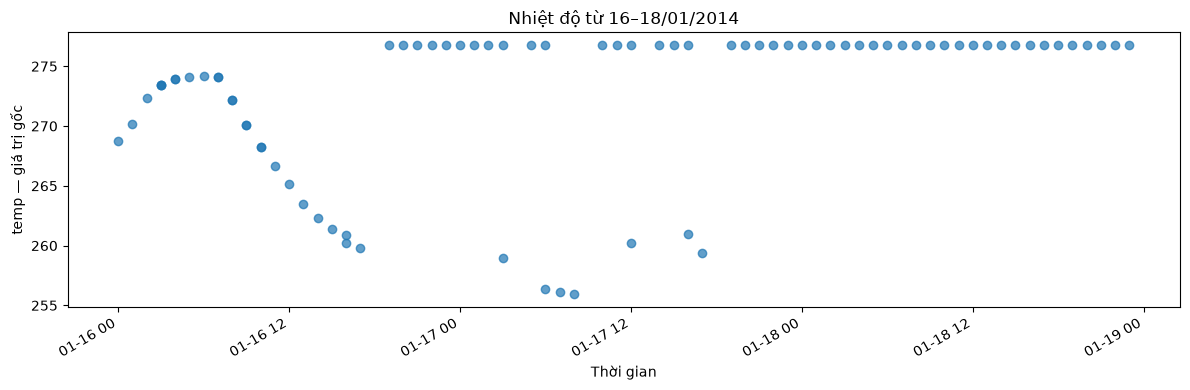

In [12]:
import matplotlib.pyplot as plt

# Tạo bản xem xét riêng, giữ nguyên df_raw
time_view = df_raw.assign(date_time_check=date_time_parsed)

# Lấy ngày nghi vấn và hai ngày lân cận
context = time_view.loc[
    (time_view["date_time_check"] >= "2014-01-16")
    & (time_view["date_time_check"] < "2014-01-19")
].sort_values("date_time_check")

focus = context.loc[
    (context["date_time_check"] >= "2014-01-17")
    & (context["date_time_check"] < "2014-01-18")
]

# Giữ index gốc để có thể truy lại từng dòng
display(focus[[
    "date_time_check", "temp", "clouds_all",
    "weather_main", "weather_description", "traffic_volume"
]])

# Scatter hiển thị mọi mức nhiệt độ, kể cả khi cùng timestamp
fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(context["date_time_check"], context["temp"], alpha=0.7)

ax.set(
    title="Nhiệt độ từ 16–18/01/2014",
    xlabel="Thời gian",
    ylabel="temp — giá trị gốc"
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Nhận xét:
- Phạm vi đối chiếu gồm biểu đồ nhiệt độ từ 16-18/01/2014, bảng chi tiết ngày 17/01 và các bản ghi CSV gốc ngày 16 và 18/01.
- Ngày `16/01/2014`, `temp` tăng từ 268.71 lúc 00:00 lên mức cao nhất buổi sáng 274.15 lúc 06:00; lúc 07:00 là 274.12. Sau đó các giá trị quan sát giảm xuống 259.79 lúc 17:00. Không có bản ghi lúc 18:00 trong ngày này; từ 19:00 đến 23:00, các bản ghi đều có `temp = 276.793`, tạo bước nhảy so với quan sát lúc 17:00.
- Ngày `17/01/2014` xuất hiện các mức nhiệt độ khác nhau trong cùng timestamp tại 03:00, 06:00, 12:00 và 16:00. Vì vậy, sự bất nhất không chỉ nằm trong khoảng 06:00-10:00.
- Cụ thể, tại `2014-01-17 06:00:00`, hai dòng index 11546 và 11547 có `temp` lần lượt là 276.793 và 256.360, chênh lệch 20.433; cả hai cùng có `traffic_volume = 5441`. Hai dòng cũng khác `clouds_all` (64 và 40) và `weather_description` (`broken clouds` và `scattered clouds`).
- Trong bảng ngày 17/01, bộ giá trị `temp = 276.793`, `clouds_all = 64`, `weather_main = Clouds` và `weather_description = broken clouds` lặp ở 17 trong tổng số 24 bản ghi, xen kẽ với các bản ghi có `temp` khoảng 255.920-261.000. Đây là mẫu lặp cần được ghi nhận để kiểm tra thêm nguồn dữ liệu.
- Ngày `18/01/2014`, cả 24 bản ghi từ 00:00 đến 23:00 đều có `temp = 276.793`, không chỉ là hầu hết các giá trị cao hơn 275.
- Biểu đồ thể hiện rõ dải giá trị 276.793 lặp qua nhiều giờ và các điểm thấp hơn trong ngày 17/01. Kết quả xác nhận sự bất nhất giữa các quan sát cùng thời điểm và một mẫu giá trị lặp kéo dài; chưa đủ căn cứ xác định đó là lỗi đo, giá trị điền sẵn hoặc kết luận bản ghi nào đúng. Không đánh giá dữ liệu sai chỉ vì nhiệt độ không tăng hoặc giảm theo một quy luật ngày đêm giả định.
- Giữ nguyên dữ liệu gốc và ghi nhận trường hợp này để xác minh nguồn hoặc quy tắc xử lý trước khi tổng hợp theo giờ; chưa xóa các điểm thấp hơn hay lấy trung bình một cách mặc định.

## Kiểm tra thứ tự thời gian và các giờ bị thiếu

In [13]:
# Kiểm tra thứ tự bản ghi hiện tại, cho phép timestamp bằng nhau
print(
    "Đã sắp xếp theo thời gian:",
    date_time_parsed.is_monotonic_increasing
)
print(
    "Số lần thời gian đi lùi:",
    date_time_parsed.diff().lt(pd.Timedelta(0)).sum()
)

# Xác nhận timestamp nằm đúng mốc giờ trước khi tìm giờ thiếu
if date_time_parsed.ne(date_time_parsed.dt.floor("h")).any():
    raise ValueError("Có timestamp lệch mốc giờ, cần kiểm tra riêng.")

# Mỗi timestamp chỉ tính một lần khi kiểm tra độ phủ thời gian
observed_hours = pd.DatetimeIndex(
    date_time_parsed.unique()
).sort_values()

expected_hours = pd.date_range(
    start=observed_hours.min(),
    end=observed_hours.max(),
    freq="h"
)

missing_hours = expected_hours.difference(observed_hours)

print("Số mốc giờ kỳ vọng:", len(expected_hours))
print("Số mốc giờ có dữ liệu:", len(observed_hours))
print("Số mốc giờ thiếu:", len(missing_hours))
print(f"Tỷ lệ giờ thiếu: {len(missing_hours) / len(expected_hours):.2%}")

display(pd.DataFrame({
    "missing_date_time": missing_hours[:20]
}))

Đã sắp xếp theo thời gian: True
Số lần thời gian đi lùi: 0
Số mốc giờ kỳ vọng: 52551
Số mốc giờ có dữ liệu: 40575
Số mốc giờ thiếu: 11976
Tỷ lệ giờ thiếu: 22.79%


,missing_date_time
0,2012-10-03 07:00:00
1,2012-10-03 10:00:00
2,2012-10-03 11:00:00
3,2012-10-03 17:00:00
4,2012-10-05 02:00:00
5,2012-10-05 04:00:00
6,2012-10-06 03:00:00
7,2012-10-07 01:00:00
8,2012-10-07 02:00:00
9,2012-10-09 03:00:00


Nhận xét:
- Các bản ghi hiện được sắp xếp theo thời gian không giảm (`True`), không có lần timestamp đi lùi (`0`). Kết quả này cho phép các timestamp bằng nhau và không có nghĩa là mỗi giờ chỉ có một dòng hoặc chuỗi không bị thiếu giờ.
- Trên lưới giờ từ `2012-10-02 09:00:00` đến `2018-09-30 23:00:00`, có 52.551 mốc giờ kỳ vọng nhưng chỉ 40.575 mốc giờ có dữ liệu. Thiếu 11.976 mốc giờ, tương ứng 22.79% số mốc giờ trong khoảng quan sát, theo cách biểu diễn timestamp hiện có trong CSV.
- Số mốc giờ có dữ liệu được đếm theo timestamp duy nhất, không phải theo tổng số 48.204 dòng. Các bản ghi lặp tại cùng thời điểm không bù được những giờ không có bản ghi.
- Kết quả này không mâu thuẫn với việc không phát hiện null hoặc chuỗi rỗng trước đó: phép kiểm tra null xét các ô trong những dòng đang có, còn phép kiểm tra giờ thiếu phát hiện các mốc thời gian hoàn toàn không có dòng dữ liệu. Giờ không có bản ghi không đồng nghĩa với `traffic_volume = 0`.
- Bảng minh họa chỉ hiển thị 20 mốc giờ thiếu đầu tiên; chưa đủ để kết luận toàn bộ dữ liệu thiếu rải rác hay có những đoạn gián đoạn dài. Cần thống kê các đoạn thiếu liên tiếp và phân bố thiếu theo thời gian.
- Trước khi tạo đặc trưng lưu lượng giờ trước hoặc cùng giờ hôm trước, cần thống nhất cách xử lý timestamp lặp và căn chỉnh theo mốc giờ thực sự. Không dùng vị trí dòng để mặc định `shift(1)` là một giờ trước hoặc `shift(24)` là cùng giờ hôm trước khi chuỗi còn lặp và thiếu giờ. Chưa tự động bổ sung hoặc điền giá trị cho các mốc thiếu.

## Thống kê các đoạn thiếu giờ liên tiếp

In [14]:
# Dùng danh sách giờ thiếu đã xác định ở bước trước
missing_df = pd.DataFrame({
    "missing_time": missing_hours
}).sort_values("missing_time")

# Bắt đầu đoạn mới khi hai mốc thiếu không cách nhau đúng 1 giờ
missing_df["segment"] = (
    missing_df["missing_time"]
    .diff()
    .ne(pd.Timedelta(hours=1))
    .cumsum()
)

# Thống kê điểm bắt đầu, kết thúc và số giờ thiếu mỗi đoạn
missing_runs = (
    missing_df.groupby("segment")
    .agg(
        start=("missing_time", "min"),
        end=("missing_time", "max"),
        hours_missing=("missing_time", "size")
    )
    .reset_index(drop=True)
    .sort_values("hours_missing", ascending=False)
)

print("Số đoạn thiếu:", len(missing_runs))
print("Tổng số giờ thiếu:", missing_runs["hours_missing"].sum())
print(
    "Đoạn thiếu dài nhất:",
    missing_runs["hours_missing"].max()
    if not missing_runs.empty else 0,
    "giờ"
)

display(missing_runs.head(10))

Số đoạn thiếu: 2588
Tổng số giờ thiếu: 11976
Đoạn thiếu dài nhất: 7386 giờ


,start,end,hours_missing
895,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
663,2013-10-27 02:00:00,2013-11-06 03:00:00,242
901,2015-06-14 21:00:00,2015-06-19 17:00:00,117
782,2014-04-29 09:00:00,2014-05-04 04:00:00,116
1023,2015-10-23 12:00:00,2015-10-27 07:00:00,92
888,2014-07-27 17:00:00,2014-07-30 08:00:00,64
415,2013-08-31 01:00:00,2013-09-01 22:00:00,46
905,2015-06-22 19:00:00,2015-06-24 03:00:00,33
892,2014-08-02 03:00:00,2014-08-03 10:00:00,32
418,2013-09-03 03:00:00,2013-09-04 07:00:00,29


Nhận xét/Đánh giá:
- Phát hiện 2.588 đoạn thiếu liên tiếp, tổng cộng 11.976 mốc giờ, khớp kết quả kiểm tra trước.
- Đoạn dài nhất gồm 7.386 giờ, từ 08/08/2014 02:00 đến 11/06/2015 19:00, tương đương khoảng 308 ngày.
- Riêng đoạn này chiếm khoảng 61,67% tổng số giờ thiếu; dữ liệu còn có những đoạn gián đoạn kéo dài nhiều ngày khác.
- Chưa xác định nguyên nhân thiếu; cần xem độ phủ theo thời gian trước khi lựa chọn cách xử lý.

## Kiểm tra độ phủ dữ liệu theo tháng

In [15]:
# Đếm các mốc giờ theo tháng, mỗi timestamp chỉ tính một lần
expected_by_month = pd.Series(
    expected_hours.to_period("M")
).value_counts()

observed_by_month = pd.Series(
    observed_hours.to_period("M")
).value_counts()

monthly_coverage = pd.DataFrame({
    "expected_hours": expected_by_month,
    "observed_hours": observed_by_month
}).fillna(0).astype(int).sort_index()

monthly_coverage.index.name = "month"

monthly_coverage["missing_hours"] = (
    monthly_coverage["expected_hours"]
    - monthly_coverage["observed_hours"]
)

monthly_coverage["missing_pct"] = (
    monthly_coverage["missing_hours"]
    / monthly_coverage["expected_hours"] * 100
).round(2)

print("Tổng giờ thiếu:", monthly_coverage["missing_hours"].sum())

# Xem 15 tháng có tỷ lệ thiếu cao nhất
display(
    monthly_coverage
    .sort_values("missing_pct", ascending=False)
    .head(20)
)

Tổng giờ thiếu: 11976


,expected_hours,observed_hours,missing_hours,missing_pct
month,,,,
2014-10,744,0,744,100.00
2014-11,720,0,720,100.00
2014-12,744,0,744,100.00
2015-01,744,0,744,100.00
2015-02,672,0,672,100.00
2015-03,744,0,744,100.00
2015-04,720,0,720,100.00
2014-09,720,0,720,100.00
2015-05,744,0,744,100.00


Nhận xét/Đánh giá:
- Tổng số giờ thiếu theo tháng là 11.976, khớp với các phép kiểm tra trước.
- Khoảng gián đoạn dài nhất gồm 7.386 mốc giờ, từ 08/08/2014 02:00 đến 11/06/2015 19:00; trong đó chín tháng trọn vẹn từ 09/2014 đến 05/2015 thiếu 100%.
- Hai tháng biên 08/2014 và 06/2015 có tỷ lệ thiếu cả tháng lần lượt 83,47% và 79,31%, bao gồm phần thuộc khoảng gián đoạn lớn cùng các giờ thiếu khác trong tháng.
- Các tháng có tỷ lệ thiếu trên 40% nằm trong giai đoạn 10/2013–12/2015 nhưng không liên tục; riêng 09/2013 có tỷ lệ thiếu đúng 40%.
- Dữ liệu thiếu tập trung theo giai đoạn; chưa xác định nguyên nhân và chưa tự động bổ sung giá trị cho các giờ thiếu.


## Kiểm tra thống kê tổng quan của các cột số

In [16]:
numeric_check_cols = [
    "temp", "rain_1h", "snow_1h",
    "clouds_all", "traffic_volume"
]

# Thống kê trên dữ liệu gốc, chưa tổng hợp theo giờ
numeric_summary = df_raw[numeric_check_cols].describe(
    percentiles=[0.01, 0.50, 0.99]
).T

display(numeric_summary)

,count,mean,std,min,1%,50%,99%,max
temp,48204.0,281.205870,13.338232,0.0,250.7803,282.45,302.82,310.07
rain_1h,48204.0,0.334264,44.789133,0.0,0.0000,0.00,3.27,9831.30
snow_1h,48204.0,0.000222,0.008168,0.0,0.0000,0.00,0.00,0.51
clouds_all,48204.0,49.362231,39.015750,0.0,0.0000,64.00,92.00,100.00
traffic_volume,48204.0,3259.818355,1986.860670,0.0,257.0000,3380.00,6701.97,7280.00


Nhận xét:
- `temp`; có min = 0 cách xa với 1% là 250.7803, với đơn KelVin 0 K không thể xảy ra trong thực tế, cần lọc xem temp =0 để xác định số lượng , thời điểm trước khi kết luận.
- `rain_1h`: median và mốc 1% đều bằng 0, mốc 99% là 3.27 nhưng giá trị lớn nhất là 9831.30; độ lệch chuẩn (44.79) lớn hơn mean (0.334) rất nhiều. Đây là dấu hiệu có giá trị cực lớn so với phần còn lại, cần xác định số dòng và thời điểm cụ thể. Chưa đủ căn cứ để kết luận đó là lỗi nhập liệu.
 - `clouds_all`: nằm trong khoảng 0–100, phù hợp với thang phần trăm. Median (64) cao hơn mean (49.36) và độ lệch chuẩn lớn (39.02), cho thấy phân phối không đối xứng.
- `traffic_volume`: giá trị nhỏ nhất là 0.0, mốc 1% là 257, mốc 99% là 6701.97 và max là 7280. Phía trên không thấy giá trị cực đoan so với mốc 99%. Giá trị min = 0 cần được kiểm tra thêm (số dòng, thời điểm) trước khi kết luận.
- Thống kê tính trên dữ liệu gốc, chưa tổng hợp theo giờ, nên các timestamp lặp được tính nhiều lần; mean và std chỉ mang tính tham khảo.
- Bảng này chỉ cho thấy dấu hiệu nghi ngờ ở `temp`, `rain_1h` và `traffic_volume`. Bước tiếp theo là lọc các dòng tương ứng để xác nhận.

### Đếm và xem các dòng nghi ngờ

In [17]:
# Chỉ xem dữ liệu, không sửa df_raw
view_cols = [
    "date_time", "temp", "rain_1h", "snow_1h",
    "clouds_all", "weather_main", "traffic_volume"
]

temp_zero = df_raw.loc[df_raw["temp"] == 0]
rain_max = df_raw.loc[df_raw["rain_1h"] == df_raw["rain_1h"].max()]
traffic_zero = df_raw.loc[df_raw["traffic_volume"] == 0]

print("Số dòng temp = 0:", len(temp_zero))
print("Số dòng rain_1h = giá trị lớn nhất:", len(rain_max))
print("Số dòng traffic_volume = 0:", len(traffic_zero))

print("\n--- temp = 0 ---")
display(temp_zero[view_cols])

print("\n--- rain_1h lớn nhất ---")
display(rain_max[view_cols])

print("\n--- traffic_volume = 0 ---")
display(traffic_zero[view_cols])

Số dòng temp = 0: 10
Số dòng rain_1h = giá trị lớn nhất: 1
Số dòng traffic_volume = 0: 2

--- temp = 0 ---


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume
11898,2014-01-31 03:00:00,0.0,0.0,0.0,0,Clear,361
11899,2014-01-31 04:00:00,0.0,0.0,0.0,0,Clear,734
11900,2014-01-31 05:00:00,0.0,0.0,0.0,0,Clear,2557
11901,2014-01-31 06:00:00,0.0,0.0,0.0,0,Clear,5150
11946,2014-02-02 03:00:00,0.0,0.0,0.0,0,Clear,291
11947,2014-02-02 04:00:00,0.0,0.0,0.0,0,Clear,284
11948,2014-02-02 05:00:00,0.0,0.0,0.0,0,Clear,434
11949,2014-02-02 06:00:00,0.0,0.0,0.0,0,Clear,739
11950,2014-02-02 07:00:00,0.0,0.0,0.0,0,Clear,962
11951,2014-02-02 08:00:00,0.0,0.0,0.0,0,Clear,1670



--- rain_1h lớn nhất ---


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume
24872,2016-07-11 17:00:00,302.11,9831.3,0.0,75,Rain,5535



--- traffic_volume = 0 ---


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume
25186,2016-07-23 18:00:00,296.68,0.0,0.0,40,Rain,0
25191,2016-07-23 23:00:00,295.90,0.0,0.0,90,Haze,0


Nhận xét:
- Có 10 dòng `temp = 0`, chia thành hai đoạn liên tiếp: 4 dòng (31/01/2014, 03:00–06:00) và 6 dòng (02/02/2014, 03:00–08:00). Các dòng này đều có `rain_1h`, `snow_1h`, `clouds_all` bằng 0 và `weather_main = Clear`; `traffic_volume` có giá trị bình thường. 0 K không thể xảy ra trong thực tế; chưa xác định nguyên nhân.
- Có 1 dòng `rain_1h = 9831.3` (2016-07-11 17:00), các cột khác của dòng này đều hợp lý (`temp = 302.11`, `traffic_volume = 5535`). cực lớn so với phân bố quan sát được chưa xác định nguyên nhân và cần  xem ngữ cảnh các giờ lân cận để có thêm kết luận.
- Có 2 dòng `traffic_volume = 0` vào 2016-07-23 lúc 18:00 và 23:00, không liền nhau; các cột khác bình thường. Cần xem ngữ cảnh các giờ xung quanh để biết đây là giá trị lẻ hay một đoạn bất thường.

### Xem ngữ cảnh xung quanh

In [18]:
def show_context(rows, before=3, after=3, title=""):
    """In các dòng ngay trước và sau nhóm dòng nghi ngờ."""
    start = max(rows.index.min() - before, df_raw.index.min())
    end = min(rows.index.max() + after, df_raw.index.max())
    print(f"--- {title} (index {start} đến {end}) ---")
    display(df_raw.loc[start:end, view_cols])

# rain_1h: một dòng duy nhất
show_context(rain_max, title="Quanh rain_1h lớn nhất")

# traffic_volume = 0: mở rộng cửa sổ vì chưa biết là dòng lẻ hay cả đoạn
show_context(traffic_zero, before=5, after=5, title="Quanh traffic_volume = 0")

# temp = 0: có thể gồm nhiều đoạn, nên xem từng đoạn một
temp_zero_starts = temp_zero.index.to_series().diff().ne(1).cumsum()
for _, part in temp_zero.groupby(temp_zero_starts):
    show_context(part, before=3, after=3, title="Quanh đoạn temp = 0")

--- Quanh rain_1h lớn nhất (index 24869 đến 24875) ---


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume
24869,2016-07-11 14:00:00,300.18,0.0,0.0,90,Clouds,4456
24870,2016-07-11 15:00:00,300.81,0.0,0.0,75,Thunderstorm,4858
24871,2016-07-11 16:00:00,301.48,0.0,0.0,75,Thunderstorm,5934
24872,2016-07-11 17:00:00,302.11,9831.3,0.0,75,Rain,5535
24873,2016-07-11 18:00:00,302.54,0.0,0.0,75,Thunderstorm,3900
24874,2016-07-11 19:00:00,302.39,0.0,0.0,75,Clouds,2856
24875,2016-07-11 20:00:00,302.45,0.0,0.0,75,Thunderstorm,2506


--- Quanh traffic_volume = 0 (index 25181 đến 25196) ---


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume
25181,2016-07-23 15:00:00,295.55,0.00,0.0,75,Thunderstorm,3
25182,2016-07-23 16:00:00,295.22,10.67,0.0,90,Rain,7
25183,2016-07-23 16:00:00,295.22,10.67,0.0,90,Mist,7
25184,2016-07-23 17:00:00,295.54,0.51,0.0,90,Rain,5
25185,2016-07-23 17:00:00,295.54,0.51,0.0,90,Mist,5
25186,2016-07-23 18:00:00,296.68,0.00,0.0,40,Rain,0
25187,2016-07-23 19:00:00,297.48,0.00,0.0,40,Clouds,1
25188,2016-07-23 20:00:00,297.21,0.00,0.0,20,Clouds,5
25189,2016-07-23 21:00:00,296.47,0.00,0.0,20,Clouds,2
25190,2016-07-23 22:00:00,295.96,0.00,0.0,75,Clouds,1


--- Quanh đoạn temp = 0 (index 11895 đến 11904) ---


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume
11895,2014-01-31 00:00:00,255.93,0.0,0.0,0,Clear,644
11896,2014-01-31 01:00:00,255.93,0.0,0.0,0,Clear,390
11897,2014-01-31 02:00:00,255.93,0.0,0.0,0,Clear,313
11898,2014-01-31 03:00:00,0.00,0.0,0.0,0,Clear,361
11899,2014-01-31 04:00:00,0.00,0.0,0.0,0,Clear,734
11900,2014-01-31 05:00:00,0.00,0.0,0.0,0,Clear,2557
11901,2014-01-31 06:00:00,0.00,0.0,0.0,0,Clear,5150
11902,2014-01-31 07:00:00,255.93,0.0,0.0,0,Clear,5363
11903,2014-01-31 08:00:00,255.93,0.0,0.0,0,Clear,5269
11904,2014-01-31 09:00:00,255.93,0.0,0.0,0,Clear,4721


--- Quanh đoạn temp = 0 (index 11943 đến 11954) ---


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume
11943,2014-02-02 00:00:00,255.59,0.0,0.0,0,Clear,1143
11944,2014-02-02 01:00:00,255.48,0.0,0.0,0,Clear,695
11945,2014-02-02 02:00:00,255.37,0.0,0.0,0,Clear,539
11946,2014-02-02 03:00:00,0.00,0.0,0.0,0,Clear,291
11947,2014-02-02 04:00:00,0.00,0.0,0.0,0,Clear,284
11948,2014-02-02 05:00:00,0.00,0.0,0.0,0,Clear,434
11949,2014-02-02 06:00:00,0.00,0.0,0.0,0,Clear,739
11950,2014-02-02 07:00:00,0.00,0.0,0.0,0,Clear,962
11951,2014-02-02 08:00:00,0.00,0.0,0.0,0,Clear,1670
11952,2014-02-02 09:00:00,255.62,0.0,0.0,0,Clear,2506


Nhận xét/Đánh giá:
- Hai đoạn temp = 0 nằm giữa các bản ghi có nhiệt độ khoảng 255–258; giá trị 0 không phù hợp nhiệt độ môi trường theo thang Kelvin, nhưng chưa xác định nguyên nhân.
- rain_1h = 9831.3 là điểm tăng vọt trong cửa sổ đang xem, trong khi các bản ghi lân cận hiển thị đều bằng 0; cần xác minh trước khi xử lý.
- Hai điểm traffic_volume = 0 thuộc cửa sổ có toàn bộ giá trị chỉ từ 0–8, nên cần kiểm tra phạm vi của cả đoạn lưu lượng thấp.
- Ngữ cảnh được lấy theo index dòng, không phải số giờ cố định; chưa sửa, xóa hoặc thay thế giá trị trong dữ liệu gốc.

### Kiểm tra lưu lượng quanh ngày 23/07/2016

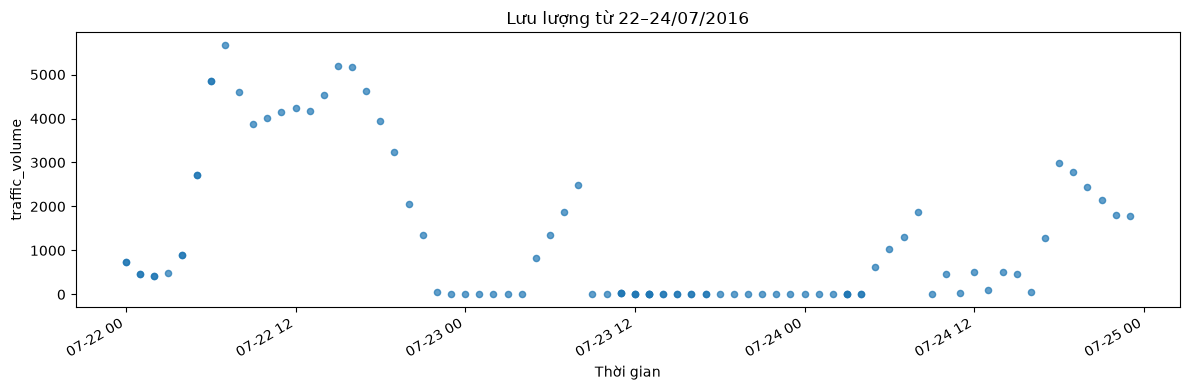

In [19]:
import matplotlib.pyplot as plt

mask = (
    date_time_parsed.ge("2016-07-22")
    & date_time_parsed.lt("2016-07-25")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(
    date_time_parsed.loc[mask],
    df_raw.loc[mask, "traffic_volume"],
    s=20,
    alpha=0.7
)
ax.set(
    title="Lưu lượng từ 22–24/07/2016",
    xlabel="Thời gian",
    ylabel="traffic_volume"
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Kiểm tra lưu lượng quanh ngày 23/07/2016

Nhận xét/Đánh giá:
- Biểu đồ ghi nhận nhiều lần lưu lượng giảm mạnh rồi tăng trở lại trong ngày 22–24/07/2016, không chỉ hai điểm bằng 0.
- Từ 23/07 09:00 đến 24/07 04:00, các giá trị traffic_volume chỉ từ 0–24, thấp rõ rệt so với các giờ ngay trước và sau.
- Ngày 24/07 còn xuất hiện các giá trị thấp xen kẽ sau lần tăng buổi sáng; từ 17:00 lưu lượng tăng trở lại.
- Cần so sánh với các ngày cùng thứ để đánh giá thêm; chưa xác định nguyên nhân và chưa sửa hoặc xóa các giá trị mục tiêu.

### So sánh lưu lượng với các ngày cùng thứ ở tuần lân cận

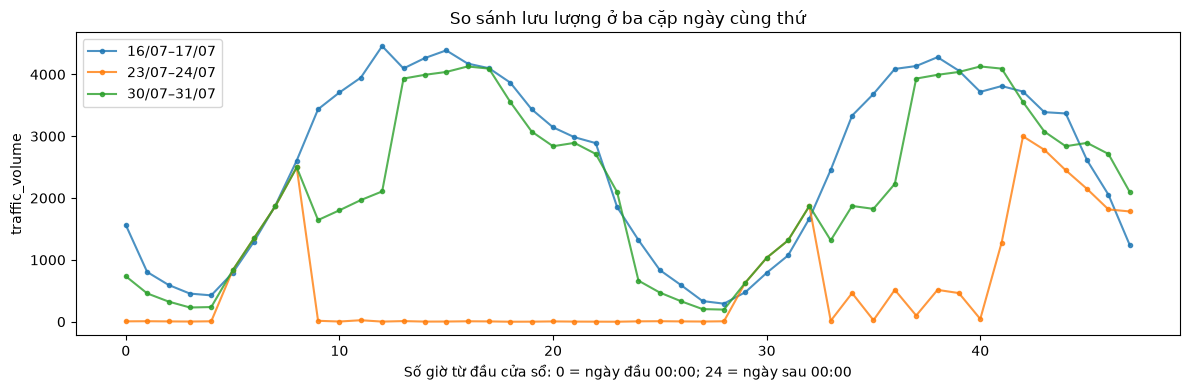

In [20]:
# Chỉ tạo chuỗi phục vụ so sánh, không sửa df_raw.
# Đã kiểm tra: các dòng cùng timestamp có cùng traffic_volume.
hourly_traffic = (
    df_raw.groupby(date_time_parsed)["traffic_volume"]
    .first()
    .sort_index()
)

comparison = pd.DataFrame(index=range(48))

for offset in [-7, 0, 7]:
    start = pd.Timestamp("2016-07-23") + pd.Timedelta(days=offset)
    hours = pd.date_range(start=start, periods=48, freq="h")

    label = f"{start:%d/%m}–{hours[-1]:%d/%m}"
    # Giờ thiếu giữ là NaN, không điền bằng 0
    comparison[label] = hourly_traffic.reindex(hours).to_numpy()

ax = comparison.plot(figsize=(12, 4), marker=".", alpha=0.8)
ax.set(
    title="So sánh lưu lượng ở ba cặp ngày cùng thứ",
    xlabel="Số giờ từ đầu cửa sổ: 0 = ngày đầu 00:00; 24 = ngày sau 00:00",
    ylabel="traffic_volume"
)
plt.tight_layout()
plt.show()

In [21]:
event = comparison["23/07–24/07"]
next_week = comparison["30/07–31/07"]

both_present = event.notna() & next_week.notna()
same_volume = both_present & event.eq(next_week)

matched = comparison.loc[same_volume, ["23/07–24/07", "30/07–31/07"]].copy()
matched.insert(1, "Giờ", matched.index.map(lambda h: f"{h % 24:02d}:00"))

display(matched)
print(f"Số giờ trùng chính xác: {same_volume.sum()}/{both_present.sum()}")

,23/07–24/07,Giờ,30/07–31/07
5,830,05:00,830
6,1350,06:00,1350
7,1868,07:00,1868
8,2497,08:00,2497
29,631,05:00,631
30,1033,06:00,1033
31,1314,07:00,1314
32,1872,08:00,1872


Số giờ trùng chính xác: 8/48


Nhận xét/Đánh giá  
- Trong 48 cặp giờ có dữ liệu, 8 cặp (16,7%) có cùng traffic_volume giữa hai cuối tuần 23–24/07 và 30–31/07/2016. Các giờ trùng tập trung từ 05:00 đến 08:00 vào cả thứ Bảy lẫn Chủ nhật.
- Theo lịch công bố, đoạn I‑94 qua trạm ATR 301 dự kiến đóng cả hai chiều từ 20:00 ngày 22/07 đến 17:00 ngày 24/07/2016. [MPR News, 22/07/2016](https://www.mprnews.org/story/2016/07/22/i94-stpaul-shutdown-twin-cities-weekend-road-woes)
- Cần đối chiếu với số đếm chiều Tây theo giờ của MnDOT để xác minh các dãy trùng. Bảng so sánh hiện tại chưa đủ để kết luận đường đã mở lại vào buổi sáng


Đã tra cứu trạm 9834, chiều Tây (WB), trên TCDS của MnDOT. Bản ghi cũ nhất hiển thị trong mục Volume Count là ngày 01/11/2018. Vì vậy, chưa xác minh được các dãy lưu lượng trùng từ 05:00 đến 08:00 giữa hai cuối tuần 23–24/07 và 30–31/07/2016 bằng nguồn này.

### Kiểm tra nhãn và tần suất của các cột phân loại


In [22]:
for col in ["holiday", "weather_main", "weather_description"]:
    counts = df_raw[col].value_counts(dropna=False)
    summary = counts.rename("so_dong").to_frame()
    summary["ty_le_pct"] = (summary["so_dong"] / len(df_raw) * 100).round(2)

    print(f"{col} — {len(summary)} nhãn")
    display(summary)

holiday — 12 nhãn


,so_dong,ty_le_pct
holiday,,
None,48143,99.87
Labor Day,7,0.01
Thanksgiving Day,6,0.01
Christmas Day,6,0.01
New Years Day,6,0.01
Martin Luther King Jr Day,6,0.01
Columbus Day,5,0.01
Veterans Day,5,0.01
Washingtons Birthday,5,0.01


weather_main — 11 nhãn


,so_dong,ty_le_pct
weather_main,,
Clouds,15164,31.46
Clear,13391,27.78
Mist,5950,12.34
Rain,5672,11.77
Snow,2876,5.97
Drizzle,1821,3.78
Haze,1360,2.82
Thunderstorm,1034,2.15
Fog,912,1.89


weather_description — 38 nhãn


,so_dong,ty_le_pct
weather_description,,
sky is clear,11665,24.20
mist,5950,12.34
overcast clouds,5081,10.54
broken clouds,4666,9.68
scattered clouds,3461,7.18
light rain,3372,7.00
few clouds,1956,4.06
light snow,1946,4.04
Sky is Clear,1726,3.58


**Nhận xét/Đánh giá**

- `holiday` có 12 nhãn; chuỗi `None` chiếm 48.143 dòng (99,87%),
  còn 61 dòng mang tên ngày lễ hoặc sự kiện.
- `weather_main` có 11 nhãn; phổ biến nhất là `Clouds` và `Clear`.
  `Smoke` và `Squall` xuất hiện ít, cần ghi nhận khi xử lý biến phân loại.
- `weather_description` có 38 nhãn. `sky is clear` và `Sky is Clear`
  khác cách viết hoa; cần xem xét chuẩn hóa dựa trên ý nghĩa của nhãn.
- Tần suất được tính theo dòng CSV; timestamp lặp có thể được tính nhiều lần.

In [23]:
holiday_rows = df_raw.loc[
    df_raw["holiday"] != "None",
    ["date_time", "holiday"]
].copy()

holiday_rows["date_time"] = pd.to_datetime(holiday_rows["date_time"])
holiday_rows["ngay"] = holiday_rows["date_time"].dt.date
holiday_rows["gio"] = holiday_rows["date_time"].dt.hour

display(holiday_rows.sort_values("date_time"))

,date_time,holiday,ngay,gio
126,2012-10-08,Columbus Day,2012-10-08,0
1123,2012-11-12,Veterans Day,2012-11-12,0
1370,2012-11-22,Thanksgiving Day,2012-11-22,0
2360,2012-12-25,Christmas Day,2012-12-25,0
2559,2013-01-01,New Years Day,2013-01-01,0
...,...,...,...,...
44441,2018-05-28,Memorial Day,2018-05-28,0
45547,2018-07-04,Independence Day,2018-07-04,0
46936,2018-08-23,State Fair,2018-08-23,0
47330,2018-09-03,Labor Day,2018-09-03,0


**Nhận xét/Đánh giá**

- Có 61 dòng mang tên ngày lễ hoặc sự kiện; toàn bộ đều có giờ là 00:00.
- Một thời điểm có thể có nhiều dòng mang cùng nhãn, chẳng hạn Labor Day
  lúc 00:00 ngày 03/09/2018 xuất hiện hai dòng.
- Cần kiểm tra các giờ còn lại trong cùng ngày để đánh giá cách sử dụng
  cột `holiday` khi tạo đặc trưng ngày lễ.

### Kiểm tra nhãn holiday trong ngày 03/09/2018

Quan sát các giờ trong ngày Labor Day để xem cột `holiday` được ghi như thế nào sau 00:00.

In [24]:
mask = date_time_parsed.dt.date == pd.Timestamp("2018-09-03").date()

display(
    df_raw.loc[mask, ["date_time", "holiday", "traffic_volume"]]
)

,date_time,holiday,traffic_volume
47330,2018-09-03 00:00:00,Labor Day,962
47331,2018-09-03 00:00:00,Labor Day,962
47332,2018-09-03 01:00:00,None,694
47333,2018-09-03 01:00:00,None,694
47334,2018-09-03 01:00:00,None,694
47335,2018-09-03 02:00:00,None,421
47336,2018-09-03 02:00:00,None,421
47337,2018-09-03 03:00:00,None,310
47338,2018-09-03 04:00:00,None,325
47339,2018-09-03 04:00:00,None,325


**Nhận xét/Đánh giá**

- Ngày 03/09/2018 có đủ 24 mốc giờ trong dữ liệu.
- Hai dòng lúc 00:00 ghi `holiday = Labor Day`; các dòng từ 01:00
  đến 23:00 ghi chuỗi `None`.
- Nếu dùng cột `holiday` trực tiếp theo từng dòng, các giờ sau 00:00
  trong ngày này sẽ không được nhận diện là ngày lễ.
- Cần kiểm tra các ngày có nhãn khác trước khi thiết kế đặc trưng theo ngày.

### Kiểm tra nhãn holiday trong các ngày có sự kiện

In [25]:
# Lấy những ngày có ít nhất một dòng mang tên lễ hoặc sự kiện
event_dates = set(holiday_rows["ngay"])

# Xem nhãn theo giờ trên toàn bộ các ngày đó
rows_on_event_dates = df_raw.loc[
    date_time_parsed.dt.date.isin(event_dates),
    ["date_time", "holiday"]
].copy()

rows_on_event_dates["gio"] = pd.to_datetime(
    rows_on_event_dates["date_time"]
).dt.hour

display(pd.crosstab(
    rows_on_event_dates["gio"],
    rows_on_event_dates["holiday"]
))

holiday,Christmas Day,Columbus Day,Independence Day,Labor Day,Martin Luther King Jr Day,Memorial Day,New Years Day,None,State Fair,Thanksgiving Day,Veterans Day,Washingtons Birthday
gio,,,,,,,,,,,,
0,6,5,5,7,6,5,6,0,5,6,5,5
1,0,0,0,0,0,0,0,55,0,0,0,0
2,0,0,0,0,0,0,0,54,0,0,0,0
3,0,0,0,0,0,0,0,55,0,0,0,0
4,0,0,0,0,0,0,0,58,0,0,0,0
5,0,0,0,0,0,0,0,59,0,0,0,0
6,0,0,0,0,0,0,0,57,0,0,0,0
7,0,0,0,0,0,0,0,57,0,0,0,0
8,0,0,0,0,0,0,0,59,0,0,0,0


**Nhận xét/Đánh giá**

- Trong các ngày đã có nhãn lễ hoặc sự kiện, tên sự kiện chỉ xuất hiện
  ở các dòng lúc 00:00; các dòng từ 01:00 đến 23:00 ghi chuỗi `None`.
- Bảng đếm theo dòng CSV, vì vậy một timestamp lặp có thể đóng góp nhiều dòng.
- Dùng trực tiếp `holiday != "None"` theo từng dòng sẽ chỉ nhận diện
  sự kiện lúc 00:00; cần xem xét cách tạo đặc trưng theo ngày.
- Kiểm tra này chưa xác định được các ngày sự kiện hoàn toàn thiếu nhãn.

### Kiểm tra số giờ có dữ liệu trong các ngày có nhãn sự kiện

In [26]:
event_coverage = rows_on_event_dates.copy()
event_coverage["date_time"] = pd.to_datetime(event_coverage["date_time"])
event_coverage["ngay"] = event_coverage["date_time"].dt.date

coverage_by_day = (
    event_coverage.groupby("ngay")["date_time"]
    .nunique()
    .rename("so_gio_co_du_lieu")
    .to_frame()
)

coverage_by_day["so_gio_thieu"] = 24 - coverage_by_day["so_gio_co_du_lieu"]

display(coverage_by_day.sort_values("so_gio_co_du_lieu"))
print("Số ngày có nhãn sự kiện:", len(coverage_by_day))
print("Số ngày thiếu ít nhất một giờ:", (coverage_by_day["so_gio_thieu"] > 0).sum())

,so_gio_co_du_lieu,so_gio_thieu
ngay,,
2013-10-14,12,12
2015-11-11,13,11
2015-11-26,14,10
2016-01-01,18,6
2015-12-25,19,5
2016-02-15,19,5
2016-05-30,21,3
2014-01-20,21,3
2014-01-01,22,2


Số ngày có nhãn sự kiện: 53
Số ngày thiếu ít nhất một giờ: 17


**Nhận xét/Đánh giá**

- Trong 53 ngày đã có nhãn lễ hoặc sự kiện, 36 ngày có đủ 24 mốc giờ
  và 17 ngày thiếu ít nhất một mốc giờ.
- Ngày 14/10/2013 có độ phủ thấp nhất trong nhóm: 12 giờ có dữ liệu,
  thiếu 12 giờ.
- Số giờ được đếm theo timestamp duy nhất, không bị tăng bởi các dòng lặp.
- Khi tạo đặc trưng sự kiện theo ngày, cần xét riêng các giờ không có bản ghi;
  kết quả này chưa kiểm tra các ngày sự kiện hoàn toàn thiếu nhãn.

### Kiểm tra số tên sự kiện trong mỗi ngày

In [27]:
labels_by_day = (
    holiday_rows.groupby("ngay")["holiday"]
    .agg(
        so_ten_su_kien="nunique",
        ten_su_kien=lambda values: ", ".join(sorted(values.unique()))
    )
)

display(labels_by_day[labels_by_day["so_ten_su_kien"] > 1])
print("Số ngày có nhiều hơn một tên:", (labels_by_day["so_ten_su_kien"] > 1).sum())

,so_ten_su_kien,ten_su_kien
ngay,,


Số ngày có nhiều hơn một tên: 0


**Nhận xét/Đánh giá**

- Trong 53 ngày có nhãn lễ hoặc sự kiện, không có ngày nào
  chứa nhiều hơn một tên sự kiện khác nhau.
- Các dòng trùng cùng tên trong một ngày chỉ được tính là một tên.
- Có thể cân nhắc dùng tên duy nhất của mỗi ngày để tạo đặc trưng
  theo ngày; độ đầy đủ của các ngày có nhãn vẫn cần được xem xét.

### Tổng hợp vấn đề của cột holiday

| Vấn đề | Bằng chứng | Nội dung cần xem xét |
|---|---|---|
| Nhãn theo giờ | Tên sự kiện chỉ xuất hiện lúc 00:00 | Cách biểu diễn sự kiện cho các giờ còn lại trong ngày |
| Giờ thiếu | 17/53 ngày có nhãn thiếu ít nhất một giờ | Cách xử lý các mốc giờ không có bản ghi |
| Tên trong ngày | Không có ngày nào có nhiều hơn một tên | Có thể cân nhắc ánh xạ một tên cho mỗi ngày |
| Độ đầy đủ của nhãn | Chưa kiểm tra ngày hoàn toàn không có nhãn | Đối chiếu lịch sự kiện bên ngoài nếu cần |

### Kiểm tra mối quan hệ giữa nhóm và mô tả thời tiết

In [28]:
weather_pairs = (
    df_raw.groupby(["weather_main", "weather_description"])
    .size()
    .rename("so_dong")
    .reset_index()
    .sort_values(["weather_main", "so_dong"], ascending=[True, False])
)

display(weather_pairs)

,weather_main,weather_description,so_dong
1,Clear,sky is clear,11665
0,Clear,Sky is Clear,1726
4,Clouds,overcast clouds,5081
2,Clouds,broken clouds,4666
5,Clouds,scattered clouds,3461
3,Clouds,few clouds,1956
8,Drizzle,light intensity drizzle,1100
6,Drizzle,drizzle,651
7,Drizzle,heavy intensity drizzle,64
9,Drizzle,shower drizzle,6


**Nhận xét/Đánh giá**

- Có 38 cặp `weather_main` và `weather_description`; mỗi mô tả chi tiết
  xuất hiện cùng một nhóm thời tiết trong dữ liệu hiện có.
- Một nhóm có thể gồm nhiều mô tả, chẳng hạn nhóm `Rain` có `light rain`,
  `moderate rain` và `freezing rain`.
- `sky is clear` và `Sky is Clear` cùng thuộc nhóm `Clear` nhưng khác
  cách viết hoa; cần xem xét chuẩn hóa trong tiền xử lý.
- Bảng đếm theo dòng CSV; việc lựa chọn giữ cột nào cần được đánh giá
  trong quá trình xây dựng và thử nghiệm mô hình.

### Kiểm tra các biến thể cách viết của mô tả thời tiết

In [29]:
description_variants = (
    df_raw[["weather_description"]]
    .drop_duplicates()
    .assign(
        dang_chuan=lambda data: (
            data["weather_description"].str.strip().str.lower()
        )
    )
    .groupby("dang_chuan")["weather_description"]
    .agg(list)
)

variants = description_variants[
    description_variants.map(len) > 1
]

display(variants)


dang_chuan
sky is clear    [sky is clear, Sky is Clear]
Name: weather_description, dtype: object

**Cell 86 — Nhận xét/Đánh giá**

- Sau khi bỏ khoảng trắng đầu/cuối và chuyển về chữ thường, có một nhóm
  mô tả trùng: `sky is clear` và `Sky is Clear`.
- Hai nhãn cùng thuộc nhóm `Clear`, với tổng cộng 13.391 dòng CSV.
- Có thể cân nhắc chuẩn hóa cách viết trong bước tiền xử lý; phép kiểm tra
  hiện tại chưa thay đổi các nhãn gốc.

### Kiểm tra các biến thể cách viết của nhóm thời tiết

In [30]:
main_variants = (
    df_raw[["weather_main"]]
    .drop_duplicates()
    .assign(
        dang_chuan=lambda data: data["weather_main"].str.strip().str.lower()
    )
    .groupby("dang_chuan")["weather_main"]
    .agg(list)
)

display(main_variants[main_variants.map(len) > 1])

Series([], Name: weather_main, dtype: object)

**Cell 89 — Nhận xét/Đánh giá**

- Không phát hiện các nhãn `weather_main` khác nhau trở thành cùng một
  nhãn sau khi bỏ khoảng trắng đầu/cuối và chuyển về chữ thường.
- Kết quả chỉ kiểm tra các biến thể trùng theo hai quy tắc trên;
  chưa kiểm tra riêng từng nhãn có khoảng trắng thừa hay không.
- Phép kiểm tra chưa thay đổi dữ liệu gốc.

### Kiểm tra khoảng trắng đầu và cuối nhãn thời tiết

In [31]:
for col in ["weather_main", "weather_description"]:
    has_outer_space = df_raw[col].ne(df_raw[col].str.strip())

    print(f"{col}: {has_outer_space.sum()} dòng có khoảng trắng đầu/cuối")
    display(df_raw.loc[has_outer_space, col].value_counts())

weather_main: 0 dòng có khoảng trắng đầu/cuối


Series([], Name: count, dtype: int64)

weather_description: 0 dòng có khoảng trắng đầu/cuối


Series([], Name: count, dtype: int64)

**Cell 92 — Nhận xét/Đánh giá**

- Không phát hiện dòng có khoảng trắng đầu hoặc cuối trong
  `weather_main` và `weather_description`.
- Hai bảng kết quả rỗng phù hợp với số dòng phát hiện bằng 0.
- Phép kiểm tra chưa thay đổi dữ liệu gốc.

### Tổng hợp kiểm tra các cột thời tiết phân loại

| Nội dung | Kết quả | Cần xem xét |
|---|---|---|
| Số nhãn | `weather_main` có 11 nhãn; `weather_description` có 38 nhãn | Lựa chọn và mã hóa đặc trưng |
| Quan hệ hai cột | Mỗi mô tả chi tiết đi cùng một nhóm trong dữ liệu hiện có | Thử nghiệm việc sử dụng hai cột |
| Cách viết | `sky is clear` và `Sky is Clear` khác chữ hoa | Cân nhắc chuẩn hóa |
| Khoảng trắng | Không phát hiện khoảng trắng đầu/cuối ở hai cột | Ghi nhận kết quả |
| Timestamp lặp | Một số giờ có nhiều nhãn thời tiết khác nhau | Chọn cách biểu diễn thời tiết theo giờ |

## Tổng hợp kết quả kiểm tra chất lượng dữ liệu

| Nội dung | Kết quả kiểm tra | Cần xem xét khi tiền xử lý |
|---|---|---|
| Cấu trúc và ô thiếu | 48.204 dòng, 9 cột; không phát hiện null hoặc chuỗi rỗng | Duy trì kiểm tra khi đọc dữ liệu |
| Dòng trùng hoàn toàn | Có 17 dòng dư trùng trên cả 9 cột | Quy định cách loại dòng dư |
| Timestamp lặp | 5.445 timestamp lặp; `traffic_volume` nhất quán nhưng một số đầu vào thời tiết khác nhau | Chọn cách tổng hợp về một dòng mỗi giờ |
| Giờ thiếu | Thiếu 11.976/52.551 mốc giờ; đoạn dài nhất thiếu 7.386 giờ | Xác định cách xử lý giờ thiếu và tạo đặc trưng trễ |
| Giá trị số nghi ngờ | Có 10 dòng `temp = 0`, một giá trị `rain_1h = 9831.3` và mẫu nhiệt độ lặp kéo dài | Xem xét cách xử lý từng trường hợp |
| Lưu lượng thấp | Ngày 23–24/07/2016 có lưu lượng thấp trùng với lịch dự kiến đóng đường; một số giá trị buổi sáng trùng tuần sau | Đánh giá theo mục tiêu dự đoán; nguyên nhân từng giá trị chưa được xác minh |
| `holiday` | Nhãn sự kiện xuất hiện lúc 00:00; 17/53 ngày có nhãn thiếu giờ | Xem xét đặc trưng theo ngày và độ đầy đủ của nhãn |
| Nhãn thời tiết | Có 11 nhóm và 38 mô tả; hai cách viết `sky is clear` và `Sky is Clear` | Xem xét chuẩn hóa, mã hóa và tổng hợp theo giờ |